# Quantum Flowers: Projet de Session

---
## IFT3395: Fondaments de l'apprentissage machine

### Prof. Vincent Taboga
#### Hiver 2025

---
##### Group Members:
  * Jose Flores - 2032749
  * Quan Tran - XXXXXXX
  * Youssef Briki - XXXXXXX

___

# Introduction

## Problem Description

>_In Quebec, energy consumption typically peaks daily in the morning, between 6 a.m. and 9 a.m., and in the evening, between 4 p.m. and 7 p.m. These periods, called peak periods, are particularly challenging to manage, especially during extreme weather conditions, whether very hot or very cold. To reduce these peaks, Hydro-Québec offers advantageous rates to encourage users to limit their consumption during these critical periods._
>
>_An effective method to reduce consumption during peak periods is to adjust heating or air conditioning, which represent the main sources of energy consumption in a building. Thanks to thermal inertia, it is possible to use energy before the peak period to preheat or precool the building while preserving occupant comfort. To optimize these strategies, it is necessary to predict, a few hours in advance, the consumption of the heating, ventilation, and air conditioning (HVAC) system. These predictions allow anticipating peaks and implementing proactive heating control rather than reactive control._


This notebook contains an implementation of a series of machine learning models trained to predict the future CVAC consumption of Quebec/Montreal citizens given a timeseries of certain relevant features like interior/exterior temperature, humidity, etc.

In [1]:
# Some useful libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

# Data Exploration

### Prepare and Analyze Dataset

First, let's explore the dataset and analyze it in order to get a better understanding of the problem.

In [10]:
# Read CSVs

# train_dataset.csv
train_df = pd.read_csv('train_dataset.csv', parse_dates=['date'])
train_df['puissance_cvac_future'] = pd.to_numeric(train_df['puissance_cvac_future'], errors='coerce')
train_df = train_df.dropna(subset=['puissance_cvac_future'])
train_df = train_df.sort_values(by='date').reset_index(drop=True)

# test_features.csv
test_df = pd.read_csv('test_features.csv', parse_dates=['date'])
test_df = test_df.sort_values(by='date').reset_index(drop=True)

train_df.head(), test_df.head()

(   ID                date  temperature_exterieure  humidite  ensoleillement  \
 0   0 2022-01-01 00:00:00                    3.25      82.0             0.0   
 1   1 2022-01-01 00:15:00                    1.50      83.0             0.0   
 2   2 2022-01-01 00:30:00                   -0.25      84.0             0.0   
 3   3 2022-01-01 00:45:00                   -2.00      85.0             0.0   
 4   4 2022-01-01 01:00:00                   -1.95      85.0             0.0   
 
    vitesse_vent  direction_vent  temperature_interieure  puissance_cvac  \
 0           6.4           210.0               21.051795        0.874277   
 1           4.6           220.0               20.999963        0.879458   
 2           2.8           230.0               21.000107        0.946028   
 3           1.0           240.0               21.000071        1.067489   
 4           1.0           242.5               21.000084        1.127481   
 
    puissance_cvac_future  
 0               1.377693  
 1  

One of the first things we notice, is the fact that there is a column `puissance_cvac` in the training dataset that is not part of the test dataset. This poses a problem if we want to use this information to predict the `puissance_cvac_future` column (which is our main target for prediction). Namely, that we can not (trivially) use it as one of the input features during training given that we will not have access to it during inference. Nonehteless, this column provides useful information that will make the model be able to predict better, we just need to find a clever way to include it in the pipeline.

In [ ]:
# Relevant columns
feature_cols = [
    'temperature_exterieure',
    'humidite',
    'ensoleillement',
    'vitesse_vent',
    'direction_vent',
    'temperature_interieure',
]

target_col = 'puissance_cvac_future'  

timesteps = 16    # Past 4 hours
output_steps = 16 # Predict next 16 future steps

train_arr = np.array(train_df[feature_cols])
test_arr = np.array(test_df[feature_cols])

train_df.head(), test_df.head(),

test_df.shape

We now define some plotting functions in order to visually analyze the data and get a better understanding of the problem.

### Histograms of Features

We first plot some histograms to visualize the distribution of each feature.

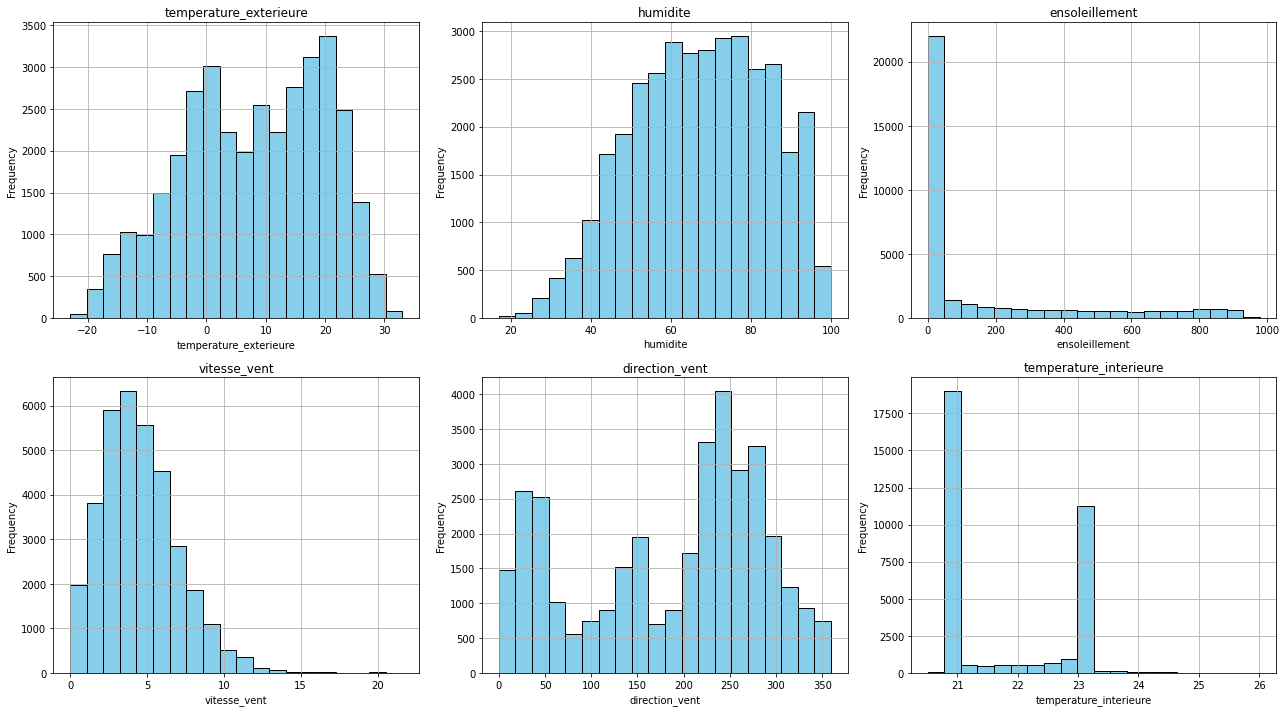

In [65]:
# Function to plot histograms of a dataframe on some given features.
def plot_feature_histograms(df, feature_cols):
    """
    Plots histograms of the given features in a grid.
    """
    n = len(feature_cols)
    rows, cols = (n // 3 + (n % 3 > 0)), 3  # Dynamically adjust grid size
    fig, axes = plt.subplots(nrows=rows, ncols=cols, figsize=(6 * cols, 5 * rows))
    axes = axes.flatten()

    for i, feature in enumerate(feature_cols):
        axes[i].hist(df[feature].dropna(), bins=20, color='skyblue', edgecolor='black')
        axes[i].set_title(f'{feature}')
        axes[i].set_xlabel(feature)
        axes[i].set_ylabel('Frequency')
        axes[i].grid(True)

    # Hide any unused subplots
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()


def plot_feature_histograms_from_array(feature_array, feature_cols):
    """
    Plots histograms of the features from a NumPy array.
    """
    n = len(feature_cols)
    rows, cols = (n // 3 + (n % 3 > 0)), 3  # Grid adjustment
    fig, axes = plt.subplots(nrows=rows, ncols=cols, figsize=(6 * cols, 5 * rows))
    axes = axes.flatten()

    for i in range(n):
        axes[i].hist(feature_array[:, i], bins=20, color='skyblue', edgecolor='black')
        axes[i].set_title(f'Distribution of {feature_cols[i]}')
        axes[i].set_xlabel(feature_cols[i])
        axes[i].set_ylabel('Frequency')
        axes[i].grid(True)

    # Hide unused subplots if any
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

# Plot histogram of training features
plot_feature_histograms(train_df, feature_cols)

# plot_feature_histograms(train_df, ['puissance_cvac'])

### Plot of Features over Time

Then we plot the timeseries of the feature data in order to see how it behaves over time.

In [66]:
def plot_feature_timeseries(df, feature_cols, date_col='date'):
    """
    Plots time series of the given features using the date column as the x-axis.
    """
    # Ensure datetime
    df[date_col] = pd.to_datetime(df[date_col])

    n = len(feature_cols)
    fig, axes = plt.subplots(nrows=n, ncols=1, figsize=(18, 4 * n), sharex=True)

    # Handle single feature case
    if n == 1:
        axes = [axes]

    for i, feature in enumerate(feature_cols):
        axes[i].plot(df[date_col], df[feature], color='tab:blue')
        axes[i].set_ylabel(feature)
        axes[i].set_title(f'{feature} over time')
        axes[i].grid(True)

    axes[-1].set_xlabel('Date')
    plt.tight_layout()
    plt.show()

def plot_feature_timeseries_from_array(feature_array, feature_cols, dates):
    """
    Plots time series of features from a NumPy array using dates as x-axis.
    """
    n = len(feature_cols)
    fig, axes = plt.subplots(nrows=n, ncols=1, figsize=(18, 4 * n), sharex=True)

    if n == 1:
        axes = [axes]

    for i in range(n):
        axes[i].plot(dates, feature_array[:, i], color='tab:blue')
        axes[i].set_ylabel(feature_cols[i])
        axes[i].set_title(f'{feature_cols[i]} over time')
        axes[i].grid(True)

    axes[-1].set_xlabel('Date')
    plt.tight_layout()
    plt.show()

# plot_feature_timeseries(train_df, feature_columns)

# plot_feature_timeseries_from_array(scaled_features, feature_columns, train_df['date'])

### Normalize Features

In order to make our model more robust and able to make better predictions, it is a good practice to normalize the features so they all fall within the same range.

✅ Scaler saved as 'lstm_scaler.pkl'


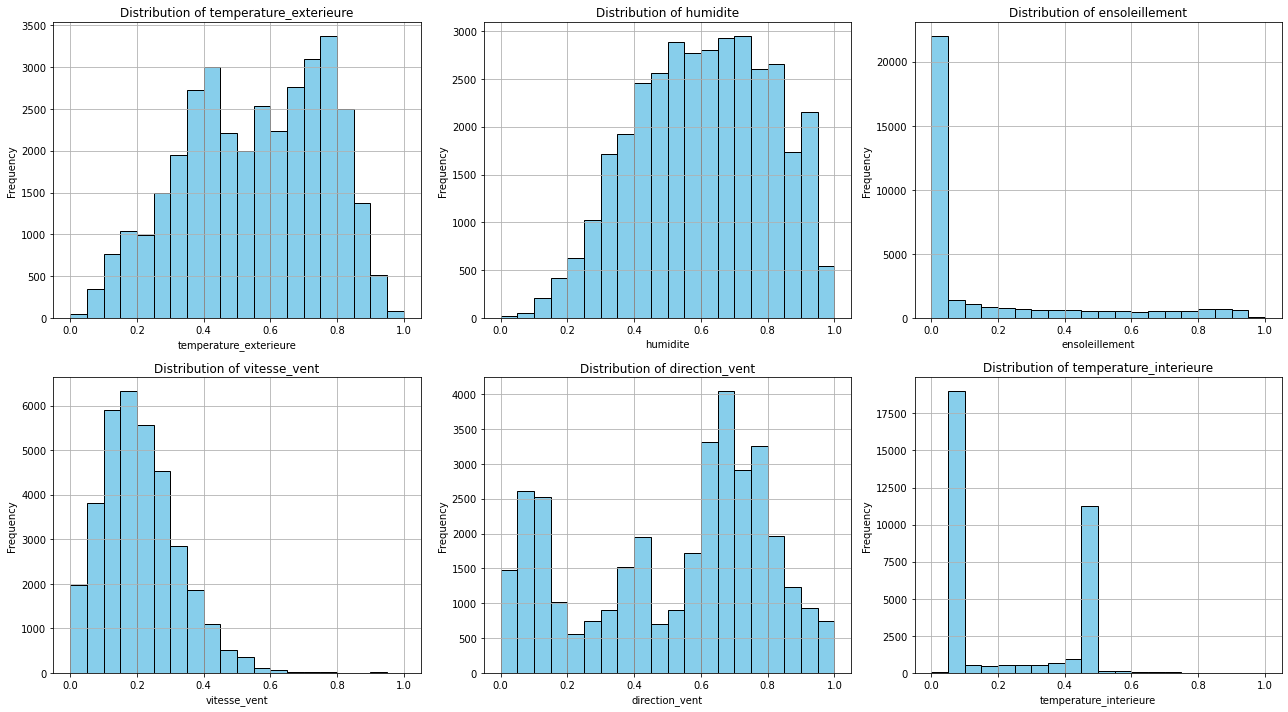

In [67]:
# Using a MinMax scaler to scale all features between 0-1
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
scaled_features = np.array(scaler.fit_transform(train_df[feature_cols]))

target_scaler = MinMaxScaler()
scaled_targets = target_scaler.fit_transform(np.array(train_df[target_col]).reshape(-1, 1)).reshape(np.array(train_df[target_col]).shape)

# Save the scaler
joblib.dump(scaler, 'lstm_scaler.pkl')
print("✅ Scaler saved as 'lstm_scaler.pkl'")


plot_feature_histograms_from_array(scaled_features, feature_cols)

# Second Approach: Trees

In [68]:
features = train_df[feature_cols]
targets = train_df[target_col]

features.shape, targets.shape

((35024, 6), (35024,))

In [70]:
train_end = int(len(features) * 0.8)

train_features = features[:train_end]
train_targets = targets[:train_end]

test_features = features[train_end:]
test_targets = targets[train_end:]

test_features.shape, test_targets.shape, train_features.shape, train_targets.shape

((7005, 6), (7005,), (28019, 6), (28019,))

## Off-the-box Decision Tree and Random Forest

In [72]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error


X_train, X_test = np.array(train_features), np.array(test_features)
y_train, y_test = np.array(train_targets), np.array(test_targets)

model_tree = DecisionTreeRegressor(random_state=69)
model_tree.fit(X_train, y_train)

model_forest = RandomForestRegressor(n_estimators=42, random_state=420)
model_forest.fit(X_train, y_train)

y_pred_tree = model_tree.predict(X_test)  # or test set if you're ready
mae_tree = mean_absolute_error(y_test, y_pred_tree)
mse_tree = mean_squared_error(y_test, y_pred_tree)
print("MAE TREE: ", mae_tree)
print("MSE TREE: ", mse_tree)

y_pred_forest = model_forest.predict(X_test)  # or test set if you're ready
mae_forest = mean_absolute_error(y_test, y_pred_forest)
mse_forest = mean_squared_error(y_test, y_pred_forest)
print("MAE FOREST: ", mae_forest)
print("MSE FOREST: ", mse_forest)


MAE TREE:  0.7341960906553365
MSE TREE:  1.1992375867250675
MAE FOREST:  0.5486272859937816
MSE FOREST:  0.6153105055719446


## Hyperparameter Tuning: Decision Tree

In [81]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeRegressor

param_grid = {
    'max_depth': [3, 4, 5, 6, 7, 8, 9, 10, 15, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['auto', 'sqrt', 'log2', None]
}

tree = DecisionTreeRegressor(random_state=42)
grid_search = GridSearchCV(tree, param_grid, cv=5, scoring='neg_mean_absolute_error', n_jobs=-1)
grid_search.fit(X_train, y_train)

print("Best params:", grid_search.best_params_)
print("Best MAE:", -grid_search.best_score_)


/home/jae/.local/lib/python3.10/site-packages/sklearn/model_selection/_validation.py:425: FitFailedWarning: 
450 fits failed out of a total of 1800.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
328 fits failed with the following error:
Traceback (most recent call last):
  File "/home/jae/.local/lib/python3.10/site-packages/sklearn/model_selection/_validation.py", line 729, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/home/jae/.local/lib/python3.10/site-packages/sklearn/base.py", line 1145, in wrapper
    estimator._validate_params()
  File "/home/jae/.local/lib/python3.10/site-packages/sklearn/base.py", line 638, in _validate_params
    validate_parameter_constraints(
  File "/home/jae/.local/lib/python

Best params: {'max_depth': 7, 'max_features': None, 'min_samples_leaf': 4, 'min_samples_split': 2}
Best MAE: 0.5334134588692507


## Hyperparameter Tuning: Random Forest

In [78]:
from sklearn.ensemble import RandomForestRegressor

param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [5, 10, 20, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'max_features': ['auto', 'sqrt']
}

rf = RandomForestRegressor(random_state=42)
grid_search_rf = GridSearchCV(rf, param_grid_rf, cv=5, scoring='neg_mean_absolute_error', n_jobs=-1)
grid_search_rf.fit(X_train, y_train)

print("Best RF params:", grid_search_rf.best_params_)
print("Best RF MAE:", -grid_search_rf.best_score_)

/home/jae/.local/lib/python3.10/site-packages/sklearn/model_selection/_validation.py:425: FitFailedWarning: 
240 fits failed out of a total of 480.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
219 fits failed with the following error:
Traceback (most recent call last):
  File "/home/jae/.local/lib/python3.10/site-packages/sklearn/model_selection/_validation.py", line 729, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/home/jae/.local/lib/python3.10/site-packages/sklearn/base.py", line 1145, in wrapper
    estimator._validate_params()
  File "/home/jae/.local/lib/python3.10/site-packages/sklearn/base.py", line 638, in _validate_params
    validate_parameter_constraints(
  File "/home/jae/.local/lib/python3

Best RF params: {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}
Best RF MAE: 0.5205214607866486


## Testing with the test dataset

In [42]:
test_df[feature_cols].head()

,temperature_exterieure,humidite,ensoleillement,vitesse_vent,direction_vent,temperature_interieure
0,-11.50,69.5,0.0,4.775,260.0,20.989188
1,-8.00,77.0,0.0,6.450,260.0,21.000051
2,-4.50,84.5,0.0,8.125,260.0,21.000019
3,-1.00,92.0,0.0,9.800,260.0,21.000015
4,-1.25,88.5,0.0,9.800,262.5,20.999918


In [44]:
TEST_FEATURES = np.array(test_df[feature_cols])

TEST_FEATURES.shape

(35024, 6)

In [55]:
tree_predictions = model_tree.predict(TEST_FEATURES)
forest_predictions = model_forest.predict(TEST_FEATURES)

In [57]:
output_df_tree = pd.DataFrame({
    'ID': test_df['ID'],
    'predictions': tree_predictions
})

output_df_tree.to_csv('tree_predictions.csv', index=False)

print("Predictions saved to 'tree_predictions.csv'")

output_df_forest = pd.DataFrame({
    'ID': test_df['ID'],
    'predictions': forest_predictions
})

output_df_forest.to_csv('forest_predictions.csv', index=False)

print("Predictions saved to 'forest_predictions.csv'")

Predictions saved to 'tree_predictions.csv'
Predictions saved to 'forest_predictions.csv'


# RNNs/LSTMs

# Model Architecture: Model A

One possibility of tackling the problem, given the limitation mentioned a few cells above (missing `puissance_cvac` column at inference time), is to design a *two-model system*.

The first model of this system will be in charge of predicting the column `puissance_cvac` based on the other input features. Then, a second model will be in charge of predicting our target `puissance_cvac_future`, taking into account both the rest of the input features as well as the predicted `puissance_cvac` values.

## Linear Regression

One possible model that would work well as the first model in our system, is a *Linear Regression* model. This a very simple model and it will serve as a good starting point on top of which we can build later, if needed.

In [7]:
feature_cols_reg = [
    'temperature_exterieure',
    'humidite',
    'ensoleillement',
    'vitesse_vent',
    'direction_vent',
    'temperature_interieure'
]

In [83]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.preprocessing import MinMaxScaler


X_reg = train_df[feature_cols_reg].values
y_reg = train_df['puissance_cvac_future'].values  # Predict CURRENT HVAC power, not future yet

# Scale features
scaler_reg = MinMaxScaler()
X_scaled = scaler_reg.fit_transform(X_reg)

# Save the scaler
joblib.dump(scaler_reg, 'reg_scaler.pkl')
print("✅ Scaler saved as 'reg_scaler.pkl'")

y_reg_scaler = MinMaxScaler()
y_reg_scaled = y_reg_scaler.fit_transform(y_reg.reshape(-1, 1))

# Save the y_scaler
joblib.dump(y_reg_scaler, 'y_reg_scaler.pkl')

✅ Scaler saved as 'reg_scaler.pkl'


['y_reg_scaler.pkl']

### Instantiate Model

In [10]:
linear = LinearRegression()

### Train Model

In [88]:
# TODO: Manually implement the training loop.
linear.fit(X_scaled, y_reg)

LinearRegression()

### Evaluate Model

In [89]:
y_pred_linear = linear.predict(X_scaled)

rmse = mean_squared_error(y_reg, y_pred_linear)
mae = mean_absolute_error(y_reg, y_pred_linear)

print(f"Linear Model RMSE: {rmse:.2f}")
print(f"Linear Model MAE: {mae:.2f}")

Linear Model RMSE: 1.08
Linear Model MAE: 0.81


In [13]:
print(train_df['puissance_cvac'].min(), train_df['puissance_cvac'].max(), train_df['puissance_cvac'].mean())

0.0 10.1842084996189 1.5288504124602837


### Plot Predicted vs. Actual values - Linear Regression

In [98]:
# Define plotting functions to use with different trained models
import matplotlib.pyplot as plt
import numpy as np

def plot_actual_vs_predicted(y_true, y_pred, window=500, title="Actual vs Predicted HVAC Power"):
    """
    Plots actual vs predicted values over time.

    Args:
        y_true (array-like): Ground truth values.
        y_pred (array-like): Predicted values.
        window (int): Number of points to plot (for zooming).
        title (str): Title of the plot.
    """
    plt.figure(figsize=(15, 5))
    plt.plot(y_true[:window], label='Actual', color='tab:blue')
    plt.plot(y_pred[:window], label='Predicted', color='tab:orange', alpha=0.7)

    plt.xlabel('Time (Index)')
    plt.ylabel('HVAC Power')
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()

def plot_residuals(y_true, y_pred, window=500, title="Residuals Plot"):
    """
    Plots residuals (Actual - Predicted) over time.

    Args:
        y_true (array-like): Ground truth values.
        y_pred (array-like): Predicted values.
        window (int): Number of points to plot (for zooming).
        title (str): Title of the plot.
    """
    residuals = y_true - y_pred
    plt.figure(figsize=(15, 5))
    plt.scatter(range(len(residuals[:window])), residuals[:window], alpha=0.5, color='tab:purple')
    plt.axhline(0, color='red', linestyle='--')
    plt.title(title)
    plt.xlabel('Time (Index)')
    plt.ylabel('Residual (Actual - Predicted)')
    plt.grid(True)
    plt.show()

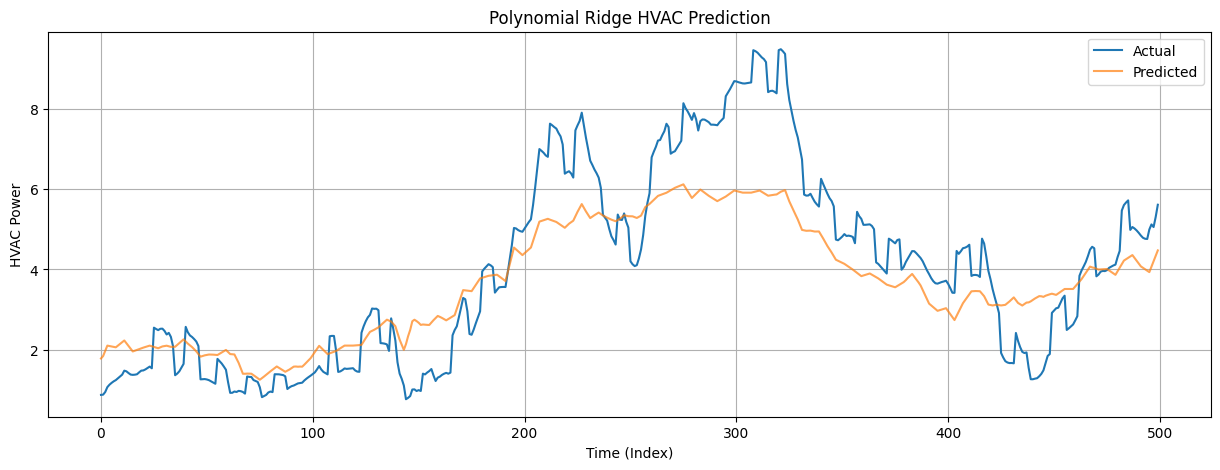

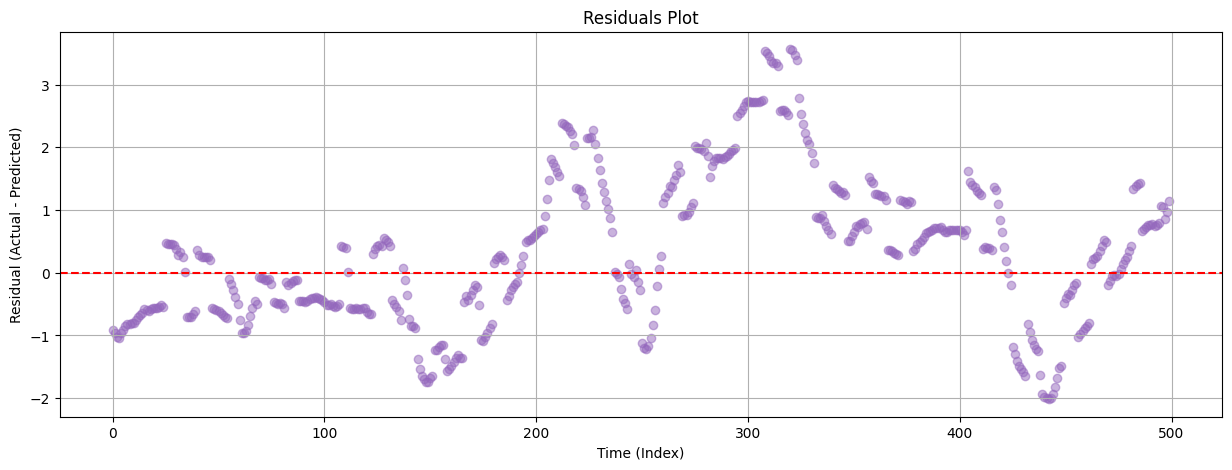

In [155]:
plot_actual_vs_predicted(y_reg, y_pred_linear, window=500, title="Polynomial Ridge HVAC Prediction")

plot_residuals(y_reg, y_pred_linear, window=500)

## Polynomial Regression

As we can see above, using just a simple Linear Regression model does not result in the best predictions.

Now, we will try with a more expressive *Polynomial Regression* model in order to better capture higher-order regularities in the data. We pair this Polynomial Regression with some *ridge regularization* to avoid overfitting as much as possible.

In [60]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [110]:
# Test with different degree and alpha values
degree = 3
alpha = 1.0

poly_ridge = make_pipeline(
    PolynomialFeatures(degree=degree, include_bias=False),
    Ridge(alpha=alpha)
)

In [62]:
# TODO: Manually implement the training loop.
train_end = int(len(X_scaled) * 0.8)

poly_ridge.fit(X_scaled[:train_end], y_reg[:train_end])

NameError: name 'X_scaled' is not defined

In [129]:
poly_ridge.fit(train_features, train_targets)

/home/jae/.local/lib/python3.10/site-packages/sklearn/linear_model/_ridge.py:200: LinAlgWarning: Ill-conditioned matrix (rcond=6.46607e-22): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


Pipeline(steps=[('polynomialfeatures',
                 PolynomialFeatures(degree=3, include_bias=False)),
                ('ridge', Ridge())])

In [130]:
y_pred_poly = poly_ridge.predict(test_features)

mse_poly = mean_squared_error(test_targets, y_pred_poly)
mae_poly = mean_absolute_error(test_targets, y_pred_poly)

print(f"Polynomial Ridge MSE: {mse_poly:.2f}")
print(f"Polynomial Ridge MAE: {mae_poly:.2f}")

Polynomial Ridge MSE: 0.48
Polynomial Ridge MAE: 0.48


In [109]:
scaled_features[train_end:].shape

(7005, 6)

### Predict and Evaluate

In [128]:
# y_pred_poly = poly_ridge.predict(X_scaled[:train_end])

# rmse_poly = mean_squared_error(y_reg[:train_end], y_pred_poly)
# mae_poly = mean_absolute_error(y_reg[:train_end], y_pred_poly)

# print(f"Polynomial Ridge RMSE: {rmse_poly:.2f}")
# print(f"Polynomial Ridge MAE: {mae_poly:.2f}")

### Save the Model

In [90]:
import joblib

joblib.dump(poly_ridge, 'models/ridge_model_train.pkl')
print("✅ Polynomial Ridge model saved as 'ridge_model_train.pkl'")

✅ Polynomial Ridge model saved as 'ridge_model_train.pkl'


### Plot Predicted vs. Actual values - Polynomial Regression

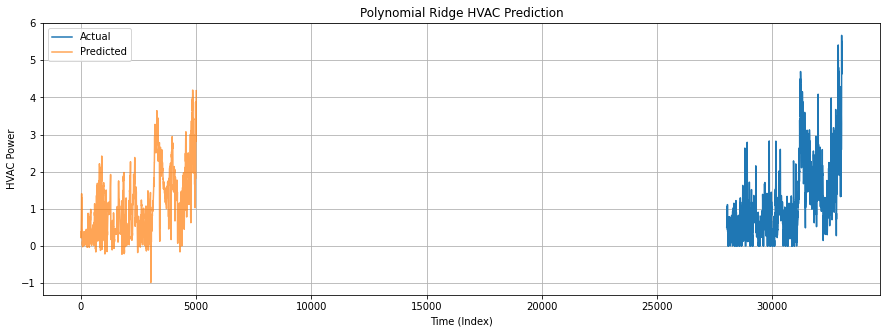

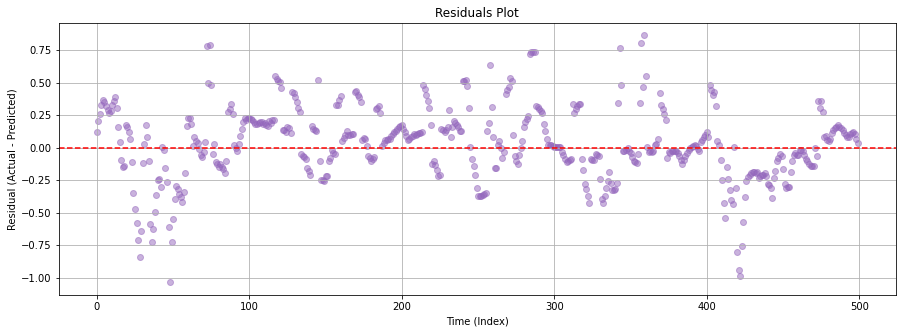

In [132]:
plot_actual_vs_predicted(test_targets, y_pred_poly, window=5000, title="Polynomial Ridge HVAC Prediction")

plot_residuals(test_targets, y_pred_poly, window=500)

# Model Architecture: Model B

Now, once we have trained the first model, *Model A*, to predict the current CVAC consumption for a given feature row, we will go ahead and design a second model to predict the CVAC consumption 16 timesteps (4 hours) later, leveraging on the predicted value of the CVAC consumption on a given timestep.

## Long-Short Term Memory (LSTM)

One very common approach to timeseries prediction is using a *Recurrent Neural Network*, or *RNN*, in order to leverage the information encoded in their hidden states, which act as a sort of memory for the network. Nonetheless, plain RNNs usually suffer from problems such as _exploding_ and _vanishing_ *gradients*.

One of the most popular variations of RNNs used to deal with these limitations, are *LSTMs* (or _Long Short-Term Memory_ networks). This type of architecture differs from regular RNNs in the fact that they use a gating mechanism that instructs the model on which information to "remember" and which one to "forget", making the model better at rembering past and recent relevant information.

For this reasons, we will begin with an implementation of an LSTM as our second model in our two-model system.

### Prepare Input Data for LSTM

In [10]:
def create_lstm_sequences_for_future_prediction(feature_array, target_array, lookback, horizon):
    X, y = [], []
    for i in range(len(feature_array) - lookback - horizon):
        target_idx = i + lookback + horizon - 1
        if np.isnan(target_array[target_idx]):
            continue  # Skip if target is NaN
        X.append(feature_array[i:i + lookback])
        y.append(target_array[target_idx])
    return np.array(X), np.expand_dims(np.array(y), axis=1)


# X_lstm, y_lstm = create_lstm_sequences_for_future_prediction(scaled_features, train_df[target_col].values, lookback=16, horizon=16)
X_lstm, y_lstm = create_lstm_sequences_for_future_prediction(scaled_features, scaled_targets, lookback=16, horizon=16)

X_lstm.shape, y_lstm.shape

((34992, 16, 6), (34992, 1))

### Split data into Train, Test and Validation sets

In [8]:
total_size = len(X_lstm)
train_end = int(0.7 * total_size)
val_end = int(0.8 * total_size)

X_train, y_train = train_df.values[feature_cols][:train_end], train_df[target_col].values[:train_end]
X_val, y_val = train_df.values[feature_cols][train_end:val_end], train_df[target_col].values[train_end:val_end]
X_test, y_test = train_df.values[feature_cols][val_end:], train_df[target_col].values[val_end:]

print("Train set:", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape, y_val.shape)
print("Test set:", X_test.shape, y_test.shape)

NameError: name 'X_lstm' is not defined

In [12]:
lookback = 16
horizon = 16
sequence_gap = lookback + horizon - 1

# Determine raw splits
total_size = len(scaled_features)
train_end = int(0.7 * total_size)
val_end = int(0.8 * total_size)

# Be careful to keep enough data for lookback + horizon
train_series_feat = scaled_features[:train_end]
train_series_tgt = train_df[target_col].values[:train_end]

val_series_feat = scaled_features[train_end - sequence_gap:val_end]
val_series_tgt = train_df[target_col].values[train_end - sequence_gap:val_end]

test_series_feat = scaled_features[val_end - sequence_gap:]
test_series_tgt = train_df[target_col].values[val_end - sequence_gap:]

# Now build sequences separately
X_train, y_train = create_lstm_sequences_for_future_prediction(train_series_feat, train_series_tgt, lookback, horizon)
X_val, y_val = create_lstm_sequences_for_future_prediction(val_series_feat, val_series_tgt, lookback, horizon)
X_test, y_test = create_lstm_sequences_for_future_prediction(test_series_feat, test_series_tgt, lookback, horizon)


print("Train set:", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape, y_val.shape)
print("Test set:", X_test.shape, y_test.shape)

Train set: (24484, 16, 6) (24484, 1)
Validation set: (3502, 16, 6) (3502, 1)
Test set: (7004, 16, 6) (7004, 1)


### Define Model Architecture

To take advantage of the already existing frameworks for neural network implementation, we will be using the `PyTorch` library to construct our model. Nonetheless, we will only use it in order to define our model's architecture. The training loo

In [13]:
# Imports
import torch
from torch.utils.data import Dataset, DataLoader

import torch.nn as nn

### Dataset Class

In [14]:
class HVACDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)
        print(self.y.shape)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

### Model Class

In [50]:
class HVAC_LSTM(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super(HVAC_LSTM, self).__init__()
        self.lstm = nn.LSTM(input_dim, hidden_dim, batch_first=True)
        self.dropout = nn.Dropout(0.4)
        # self.fc = nn.Linear(hidden_dim, output_dim)
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        lstm_out, _ = self.lstm(x)  # (batch, seq, hidden_dim)
        out = self.dropout(lstm_out[:, -1, :])
#         out = self.fc(lstm_out[:, -1, :])
        out = self.fc(out)
        return out

In [118]:
class HVAC_RNN(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super(HVAC_RNN, self).__init__()
        self.rnn = nn.RNN(input_dim, hidden_dim, num_layers=1, nonlinearity='relu', batch_first=True)
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        rnn_out, _ = self.rnn(x)
        out = self.fc(rnn_out[:, -1, :])
        return out


In [115]:
import torch
from torch.utils.data import TensorDataset, DataLoader

# Convert to PyTorch tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32)

X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val, dtype=torch.float32)

X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32)

# Wrap in datasets and loaders
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)


### Hyperparameter Set-Up

In [120]:
batch_size = 64
# train_dataset = HVACDataset(X_train, y_train)
# train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=False)
# val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle = False)


input_dim = 6  
hidden_dim = 64
output_dim = 1 

# Instantiate model
# model = HVAC_LSTM(input_dim, hidden_dim, output_dim)
model = HVAC_LSTM(input_dim=X_train.shape[2], hidden_dim=64, output_dim=1).to(device)


# Loss function
criterion = nn.MSELoss()
# Optimizer
optimizer = torch.optim.Adam(model.parameters(), lr=0.005)#, weight_decay=1e-4)
# Scheduler
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=5, factor=0.5)


### Training Loop

In [30]:
# # T
# epochs = 50

# for epoch in range(epochs):
#     model.train()
#     train_loss = 0.0
#     for X_batch, y_batch in train_loader:
#         X_batch, y_batch = X_batch.to(device), y_batch.to(device)

#         optimizer.zero_grad()
#         predictions = model(X_batch)
#         loss = criterion(predictions, y_batch)
#         loss.backward()
#         optimizer.step()

#         train_loss += loss.item() 

#     train_loss /= len(train_loader.dataset)

#     # Validation loop
#     model.eval()
#     val_loss = 0.0
#     with torch.no_grad():
#         for X_batch, y_batch in val_loader:
#             X_batch, y_batch = X_batch.to(device), y_batch.to(device)
#             predictions = model(X_batch)
#             loss = criterion(predictions, y_batch)
#             val_loss += loss.item()

#     val_loss /= len(val_loader.dataset)

#     print(f"Epoch {epoch+1}/{epochs} - Train Loss: {train_loss:.4f} - Val Loss: {val_loss:.4f}")


## Training Loop function

In [123]:
import matplotlib.pyplot as plt
from IPython.display import clear_output
import time

def train_loop(model, num_epochs, train_loader, val_loader):
    n_epochs = num_epochs
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model.to(device)
    
    # Loss function
    criterion = nn.MSELoss()
    # Optimizer
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    loss_history = []
    val_loss_history = []

    for epoch in range(n_epochs):
        model.train()
        total_loss = 0
        start_time = time.time()
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            # print(X_batch.shape, y_batch.shape)

            optimizer.zero_grad()

            output = model(X_batch) # ✅ Ensures shape (batch_size,)
            loss = criterion(output, y_batch)

            loss.backward()
            # Optional: gradient clipping
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader)
        loss_history.append(avg_loss)


        # Validation loop
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch, y_batch = X_batch.to(device), y_batch.to(device)
                predictions = model(X_batch)
                loss = criterion(predictions, y_batch)
                val_loss += loss.item() 

        val_loss /= len(val_loader.dataset)
        val_loss_history.append(val_loss)


        # scheduler.step(avg_loss)

        clear_output(wait=True)
        plt.figure(figsize=(8, 5))
        plt.plot(loss_history, label='Training Loss')
        plt.plot(val_loss_history, label='Validation Loss')  
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Training and Validation Loss over Epochs')
        plt.legend()
        plt.grid(True)
        plt.show()

        print(f"Epoch {epoch+1}/{n_epochs}, Train Loss: {avg_loss:.6f}, Val. Loss: {val_loss:.6f} Time: {time.time() - start_time:.2f}s")


### Train Model

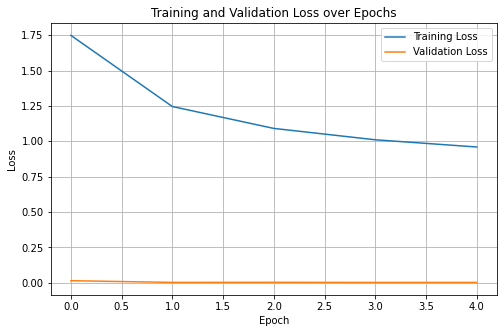

Epoch 5/300, Train Loss: 0.959745, Val. Loss: 0.002391 Time: 2.30s


KeyboardInterrupt: 

In [113]:
train_loop(model, 50, train_loader, val_loader) # LSTM

In [55]:
X_train_tensor.shape

torch.Size([24484, 16, 6])

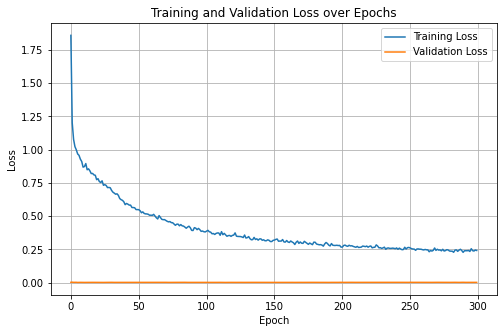

Epoch 300/300, Train Loss: 0.242053, Val. Loss: 0.002268 Time: 2.14s


In [122]:
# RNN
model_rnn = HVAC_RNN(input_dim, hidden_dim)
train_loop(model_rnn, 50, train_loader, val_loader)

### Save Model

In [23]:
torch.save(model.state_dict(), 'models/model1.pth')

### Test Model

In [225]:
# test_dataset = HVACDataset(X_test, y_test)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

len(test_loader), len(train_loader)

torch.Size([6999, 1])


(110, 383)

In [35]:
def test_model(model, test_loader):
    # Set model to eval mode
    model.eval()

    # model.eval()
    test_loss = 0
    all_preds = []
    all_targets = []

    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)

            preds = model(X_batch)

            loss = criterion(preds, y_batch)
            test_loss += loss.item()

            all_preds.append(preds.cpu())
            all_targets.append(y_batch.cpu())

    avg_test_loss = test_loss / len(test_loader)
    print(f"Test Loss (MSE): {avg_test_loss:.6f}")

In [124]:
test_model(model_rnn, test_loader)

Test Loss (MSE): 1.552999


# Model Architecture: Inference

Once we have defined and trained both models of our two-model system, it is time for inference.

## Load Test Features

In [200]:
# Load test features
test_df = pd.read_csv('test_features.csv')

## Load Pre-Trained Models

In [201]:
# Model A:
ridge_model = joblib.load('ridge_model.pkl')

# Model B:
lstm_model = HVAC_LSTM(input_dim, hidden_dim, output_dim)
lstm_model.load_state_dict(torch.load('dummy_model.pth'))
lstm_model.eval()

HVAC_LSTM(
  (lstm): LSTM(6, 64, batch_first=True)
  (dropout): Dropout(p=0.25, inplace=False)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)

## Load Scalers

In [202]:
# Model A:
reg_scaler = joblib.load('reg_scaler.pkl')

# Model B:
lstm_scaler = joblib.load('lstm_scaler.pkl')

In [133]:
!pwd

/home/jae/Desktop/UdeM/IFT3395/Projet


## Model A Predictions

In [131]:
# Scale test features
test_scaled = reg_scaler.transform(test_df[feature_cols_reg])

# Make prediction
ridge_pred = ridge_model.predict(test_scaled)

/home/jae/.local/lib/python3.10/site-packages/sklearn/base.py:458: UserWarning: X has feature names, but MinMaxScaler was fitted without feature names
  warnings.warn(


## Model B Predictions

### Add Model A predictions column to test features

In [132]:
test_df['puissance_cvac'] = ridge_pred

### Prepare Input for LSTM

In [134]:
lstm_input = lstm_scaler.transform(test_df[feature_cols])
lstm_input = np.expand_dims(lstm_input, axis=1)

### Run Inference on LSTM

In [157]:
with torch.no_grad():
    lstm_tensor = torch.tensor(lstm_input, dtype=torch.float32)
    lstm_predictions = lstm_model(lstm_tensor)  # Forward pass
    lstm_predictions = lstm_predictions.numpy().flatten()  # Convert to numpy and flatten

lstm_predictions.max(), train_df['puissance_cvac'].max()

(2.1080275, 10.1842084996189)

## Output CSV with predictions

In [151]:
output_df = pd.DataFrame({
    'ID': test_df['ID'],
    'predictions': lstm_predictions
})

output_df.to_csv('test_predictions.csv', index=False)

print("Predictions saved to 'test_predictions.csv'")

Predictions saved to 'test_predictions.csv'


# Future Approaches: XGBoost

Docs:
* https://www.reddit.com/r/MachineLearning/comments/1aoo7gc/d_how_does_xgboost_work_with_time_series/?rdt=63725

In [82]:
import xgboost as xgb
# from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score


train_end = int(len(train_df) * .8)

X_train_xgb = np.array(train_df[feature_cols].values[:train_end])
y_train_xgb = np.array(train_df[target_col].values[:train_end])

X_test_xgb = np.array(train_df[feature_cols].values[train_end:])
y_test_xgb = np.array(train_df[target_col].values[train_end:])



model_xgb = xgb.XGBRegressor(
    n_estimators=100,
    max_depth=10,
    learning_rate=0.01,
    random_state=42
)

model_xgb.fit(X_train_xgb, y_train_xgb)


y_pred = model_xgb.predict(X_test_xgb)

# # Evaluate accuracy
# accuracy = accuracy_score(y_test_xgb, y_pred)
# print("Test Accuracy: {:.2f}%".format(accuracy * 100))

# X_test_xgb.shape, y_test_xgb.shape

y_test_xgb[0:10], y_pred[0:10]

(array([0.50052402, 0.54477301, 0.55477683, 0.58453782, 0.58551163,
        0.6013299 , 0.61673633, 0.63042907, 0.64369206, 0.67181424]),
 array([0.66876036, 0.6677835 , 0.6677835 , 0.6677835 , 0.6654229 ,
        0.6663998 , 0.6789146 , 0.682626  , 0.6986309 , 0.69431025],
       dtype=float32))

## Hyperparameter Tuning: XGBoost

In [86]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_absolute_error
import xgboost as xgb
import numpy as np

# Prepare training and testing sets
# train_end = int(len(train_df) * 0.8)

# X_train_xgb = np.array(train_df[feature_cols].values[:train_end])
# y_train_xgb = np.array(train_df[target_col].values[:train_end])

# X_test_xgb = np.array(train_df[feature_cols].values[train_end:])
# y_test_xgb = np.array(train_df[target_col].values[train_end:])

# Define the model
xgb_model = xgb.XGBRegressor(random_state=42, objective='reg:squarederror')

# Parameter grid
param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [5, 10],
    'learning_rate': [0.01, 0.1],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

# Set up GridSearchCV
grid_search = GridSearchCV(
    estimator=xgb_model,
    param_grid=param_grid,
    scoring='neg_mean_absolute_error',
    cv=3,
    verbose=1,
    n_jobs=-1
)

# Fit the model
grid_search.fit(train_features, train_targets)

# Best model and evaluation
best_model = grid_search.best_estimator_
y_pred = best_model.predict(test_features)

mae = mean_absolute_error(test_targets, y_pred)
print("Best parameters:", grid_search.best_params_)
print("Test MAE:", mae)


Fitting 3 folds for each of 32 candidates, totalling 96 fits
Best parameters: {'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 100, 'subsample': 1.0}
Test MAE: 0.4798425498674746
